# Encodings

Real problems are not about bits. They are about numbers, positions, and
choices: which city to visit third, which energy level a particle is in, which
way a chain turns. Before a quantum computer can work on such a problem, we
must decide how to write each value as a pattern of bits. There is more than
one way to do it, and the choice decides how many qubits the problem needs
and how many gates each operation on it costs.

This notebook compares three standard ways to write a whole number as bits.
It counts the bits each one needs, finds the bit patterns that stand for no
value at all, and builds the operation "move to the neighboring value" in
each one to see what it costs.

## Before you start

This notebook assumes [Notebook 00](00_Bits_and_Basis_States.ipynb)
(bitstrings with bit 0 on the right, running circuits with the Sampler),
[Notebook 01](01_One_Bit_Operators.ipynb) (the NOT operator $X$), and
[Notebook 02](02_Reversible_Logic.ipynb) (XOR $\oplus$, the gates CX, SWAP
and CCX, hopping terms $a_j^\dagger a_k$, permutation matrices, and counting
the CX gates a circuit needs).

Quick check:

1. What is the binary number $110$ in decimal?
2. What does CX with control 0 and target 1 do to $|01\rangle$?
3. What does SWAP of bits 0 and 1 do to $|01\rangle$?

Answers: 6; $|11\rangle$; $|10\rangle$.

After this notebook you will be able to:

1. Write the whole numbers 0 to 7 in three different bit codes, and read a
   number back from its bits.
2. Count the bits each code needs for a given number of values, and find the
   bit patterns that stand for no value.
3. Write a function of the bits that is 0 for every pattern that stands for a
   value and positive for every other pattern.
4. Build the operation "change $m$ into $m+1$" in each code, and compare how
   many gates it costs.

## Setup

In [1]:
import sys
from pathlib import Path
from types import SimpleNamespace

import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# _runtime.py (in ../scripts) decides where circuits run:
# the Aer simulator, plus IBM hardware if asked.
# Run this notebook from its own folder (the default in Jupyter and VS Code).
sys.path.insert(0, str(Path.cwd().parent / "scripts"))
from _runtime import get_targets

np.set_printoptions(precision=3, suppress=True)

SETTINGS = SimpleNamespace(
    shots=4096,                  # runs of each circuit
    precision=0.02,              # used from Notebook 09 on
    backend="ibm_rensselaer",
    name="default",              # saved IBM account name
    skip_hardware=True,          # set to False to also run on IBM hardware
    poll_interval=20,            # seconds between hardware status checks
)
targets = get_targets(SETTINGS)
print("Running on:", [t.label for t in targets])

Running on: ['aer']


## Encoding and decoding

Suppose a problem has $N$ possible values, numbered $0, 1, \dots, N-1$. An
*encoding* is a rule that assigns each value a bitstring. *Decoding* is the
reverse: given a bitstring, find the value it stands for. An encoding must
give different values different bitstrings, so that decoding is possible.

The encoding is a choice we make, not a property of the problem. This
notebook uses $N = 8$ values and three encodings.

The first is the one you already know. The *binary encoding* writes $m$ as a
binary number. It needs $\log_2 N$ bits (rounded up when $N$ is not a power
of 2): three bits for $N = 8$.

In [2]:
N = 8


def binary(m, num_bits=3):
    return format(m, f"0{num_bits}b")


print([binary(m) for m in range(N)])

['000', '001', '010', '011', '100', '101', '110', '111']


**Check.** How many bits does the binary encoding need for $N = 100$ values?

## Gray code

In binary, neighboring numbers can differ in many bits: 3 is $011$ and 4 is
$100$, so all three bits change. The *Gray code* is a different assignment of
the same three-bit patterns, chosen so that the codes of $m$ and $m+1$ always
differ in exactly one bit. The Gray code of $m$ is

$$g = b \oplus (b \gg 1),$$

where $b$ is the binary form of $m$, $b \gg 1$ is $b$ shifted one place to the
right (bit $k+1$ moves to bit $k$, and the top bit becomes 0), and $\oplus$ is
XOR applied bit by bit. In words: bit $k$ of the Gray code is the XOR of bits
$k$ and $k+1$ of the binary code. In Python this is `m ^ (m >> 1)`, with the
bitwise operators of Notebook 02.

To compare codes we count how many bits change. The *Hamming distance*
between two bitstrings of the same length is the number of positions in which
they differ. The binary codes of 3 and 4 are at Hamming distance 3; the Gray
code is built so that the codes of $m$ and $m+1$ are always at distance 1.

### Example 1: the Gray code of 0 to 7, and decoding it

**Problem.** List the Gray codes of 0 to 7, check that neighbors differ in
one bit, and decode the Gray code $101$.

**Plan.** Apply $g = b \oplus (b \gg 1)$ to each binary code. To decode, undo
the XORs from the top bit down: the top bit of $g$ equals the top bit of $b$,
and each lower bit of $b$ is the bit above it XOR the matching bit of $g$.

**Solution.**

**Subgoal 1: encode.**

1. $m = 3$: $b = 011$ and $b \gg 1 = 001$, so $g = 011 \oplus 001 = 010$.
2. $m = 4$: $b = 100$ and $b \gg 1 = 010$, so $g = 100 \oplus 010 = 110$.
3. The code below does the same for all eight values.

**Subgoal 2: decode $g = 101$.**

4. Top bit: $b_2 = g_2 = 1$.
5. Next bit: $b_1 = b_2 \oplus g_1 = 1 \oplus 0 = 1$.
6. Last bit: $b_0 = b_1 \oplus g_0 = 1 \oplus 1 = 0$.
7. So $b = 110$, which is $m = 6$.

**Check.** Encode 6 again: $110 \oplus 011 = 101$, the code we started from.
The codes of 3 and 4, $010$ and $110$, differ only in bit 2.

**Self-explanation prompt.** In step 5, why does $b_1 = b_2 \oplus g_1$?
**Answer.** By the definition, $g_1 = b_1 \oplus b_2$. XOR both sides with
$b_2$ and use $b_2 \oplus b_2 = 0$: $g_1 \oplus b_2 = b_1$.

**Takeaway.** The Gray code uses the same bits as binary and every pattern
stands for a value; only the assignment changes, so that one step up or down
always changes one bit.

In [3]:
def gray(m, num_bits=3):
    return format(m ^ (m >> 1), f"0{num_bits}b")


def decode_gray(code):
    bits = [int(c) for c in code]          # bits[0] is the top bit
    b = [bits[0]]
    for g in bits[1:]:
        b.append(b[-1] ^ g)                # b_k = b_(k+1) XOR g_k
    return int("".join(map(str, b)), 2)


def hamming_distance(s, t):
    return sum(c != d for c, d in zip(s, t))


for m in range(N):
    step = hamming_distance(gray(m), gray(m + 1)) if m < N - 1 else None
    code = gray(m)
    line = f"m = {m}: binary {binary(m)}, Gray {code}, decodes to {decode_gray(code)}"
    if step is not None:
        line += f", bits changed to reach m+1: {step}"
    print(line)

m = 0: binary 000, Gray 000, decodes to 0, bits changed to reach m+1: 1
m = 1: binary 001, Gray 001, decodes to 1, bits changed to reach m+1: 1
m = 2: binary 010, Gray 011, decodes to 2, bits changed to reach m+1: 1
m = 3: binary 011, Gray 010, decodes to 3, bits changed to reach m+1: 1
m = 4: binary 100, Gray 110, decodes to 4, bits changed to reach m+1: 1
m = 5: binary 101, Gray 111, decodes to 5, bits changed to reach m+1: 1
m = 6: binary 110, Gray 101, decodes to 6, bits changed to reach m+1: 1
m = 7: binary 111, Gray 100, decodes to 7


**Check.** Decode the Gray code $011$.

## Unary (one-hot) encoding

The third encoding spends many more bits. The *unary* or *one-hot* encoding
uses $N$ bits, one per value, and writes $m$ by setting bit $m$ to 1 and all
others to 0. For $N = 8$, the value 3 is $00001000$.

The *Hamming weight* of a bitstring is the number of 1s in it. Every one-hot
code has Hamming weight 1, and any two one-hot codes are at Hamming distance
2.

Eight bits have $2^8 = 256$ patterns, and only 8 of them are one-hot codes. A
bitstring that the encoding assigns to some value is *valid*; any other
bitstring is *invalid*. For one-hot, a bitstring is valid exactly when its
Hamming weight is 1. Binary and Gray codes with $N = 8$ have no invalid
patterns, but they do when $N$ is not a power of 2: with three bits and
$N = 5$, the patterns for 5, 6 and 7 stand for nothing (Exercise 3).

In [4]:
def unary(m, num_bits=N):
    return format(1 << m, f"0{num_bits}b")


def decode_unary(code):
    """Return the value, or None if the bitstring is invalid."""
    if code.count("1") != 1:
        return None
    return len(code) - 1 - code.index("1")     # bit 0 is the rightmost character


print([unary(m) for m in range(N)])
print("decode 00001000 ->", decode_unary("00001000"))
print("decode 00011000 ->", decode_unary("00011000"))

['00000001', '00000010', '00000100', '00001000', '00010000', '00100000', '01000000', '10000000']
decode 00001000 -> 3
decode 00011000 -> None


Invalid bitstrings matter because a quantum computer does not know which
patterns we meant to use. A hardware error, or an operation that does not
respect the encoding, can leave the qubits in a pattern that decodes to
nothing.

**Check.** What is the Hamming distance between the binary codes of 2 and 5?

## Penalties

When a problem is written for a quantum computer, it is often written as a
function of the bits whose smallest value is the answer we want. Units 2 and
3 show how a quantum computer searches for the bitstring with the smallest
value; Unit 3's traveling-salesman notebook is one example. Here only the
function matters. For such a search to avoid invalid bitstrings, the function
must charge for them.

A *penalty* is a function of the bits that is 0 on every valid bitstring and
positive on every invalid one. For one-hot, the Hamming weight $w$ must be 1,
and the penalty used in this course is

$$\text{penalty}(x) = \Big(\sum_{k} x_k - 1\Big)^2 = (w - 1)^2.$$

In words: square how far the number of 1s is from one. Why a square, and not
the distance $|w - 1|$? Both are 0 only at $w = 1$ and positive otherwise. The
square has the advantage that it multiplies out into a sum of single bits and
products of bits (Example 2), a polynomial in the bits, which is the form
Notebook 08 turns into an operator. The absolute value does not multiply out
that way.

### Example 2: expanding the one-hot penalty

**Problem.** Expand $(x_0 + x_1 + x_2 - 1)^2$ for three bits into a sum of
single bits and products of pairs of bits, and check it on every Hamming
weight.

**Plan.** Multiply out the square, then use $x_k^2 = x_k$, which holds for
bits because $0^2 = 0$ and $1^2 = 1$.

**Solution.**

**Subgoal 1: multiply out.**

1. Write $s = x_0 + x_1 + x_2$, so the penalty is $(s - 1)^2 = s^2 - 2s + 1$.
2. Expand $s^2$: the squares give $x_0^2 + x_1^2 + x_2^2$, and each pair
   appears twice, giving $2(x_0x_1 + x_0x_2 + x_1x_2)$.

**Subgoal 2: simplify with $x_k^2 = x_k$.**

3. Replace each square: $s^2 = x_0 + x_1 + x_2 + 2(x_0x_1 + x_0x_2 + x_1x_2)$.
4. Substitute into step 1:
   $(s-1)^2 = (x_0 + x_1 + x_2) + 2(x_0x_1 + x_0x_2 + x_1x_2) - 2(x_0 + x_1 + x_2) + 1$.
5. Collect the single-bit terms:
   $(s-1)^2 = 1 - x_0 - x_1 - x_2 + 2(x_0x_1 + x_0x_2 + x_1x_2)$.

**Check.** For Hamming weight $w$, the single-bit terms sum to $w$ and there
are $w(w-1)/2$ pairs with both bits 1, so step 5 gives
$1 - w + w(w-1) = (w-1)^2$: 1 for $w = 0$, 0 for $w = 1$, 1 for $w = 2$, and
4 for $w = 3$. The code checks all eight bitstrings.

**Takeaway.** Because $x^2 = x$ for bits, every penalty built from sums of
bits becomes a constant plus single-bit terms plus products of bits. Notebook
08 turns exactly such an expression into an operator, by replacing each bit
$x_k$ with the number operator $n_k = (I - Z_k)/2$ of Notebook 01.

In [5]:
def one_hot_penalty(code):
    return (code.count("1") - 1) ** 2


def expanded_penalty(code):
    x0, x1, x2 = (int(code[-1 - k]) for k in range(3))
    return 1 - x0 - x1 - x2 + 2 * (x0 * x1 + x0 * x2 + x1 * x2)


for m in range(8):
    code = binary(m)
    weight = code.count("1")
    print(
        f"{code}: weight {weight}, (w - 1)^2 = {one_hot_penalty(code)},"
        f" expanded = {expanded_penalty(code)}"
    )

000: weight 0, (w - 1)^2 = 1, expanded = 1
001: weight 1, (w - 1)^2 = 0, expanded = 0
010: weight 1, (w - 1)^2 = 0, expanded = 0
011: weight 2, (w - 1)^2 = 1, expanded = 1
100: weight 1, (w - 1)^2 = 0, expanded = 0
101: weight 2, (w - 1)^2 = 1, expanded = 1
110: weight 2, (w - 1)^2 = 1, expanded = 1
111: weight 3, (w - 1)^2 = 4, expanded = 4


**Check.** What penalty does the one-hot code $00000000$, with no bit set,
receive?

## Adding one in binary

Each encoding stores the same values; how they differ shows up in the
operations. The simplest operation on a number is to add one. It must be
reversible to run as a gate (Notebook 02), so we add one modulo $N$: the
largest value wraps around to 0. That is a permutation of the values, so it
is a permutation matrix.

### Example 3: a circuit that adds one modulo 4

**Problem.** Build a circuit on two bits that sends the binary code of $m$ to
the binary code of $(m + 1) \bmod 4$, and check it on all four inputs.

**Plan.** Adding one in binary flips bit 0, and flips bit 1 when there is a
carry, that is, when bit 0 was 1 before the flip. Compute the carry first,
while bit 0 still holds its old value.

**Solution.**

**Subgoal 1: the carry into bit 1.**

1. Bit 1 must flip exactly when the old bit 0 is 1. That is CX with control
   0 and target 1: bit 1 becomes $b_1 \oplus b_0$.

**Subgoal 2: flip bit 0.**

2. Apply $X_0$: bit 0 becomes $\lnot b_0$.

**Subgoal 3: check all inputs.**

3. $00$: CX does nothing, $X_0$ gives $01$. ($0 \to 1$)
4. $01$: CX gives $11$, $X_0$ gives $10$. ($1 \to 2$)
5. $10$: CX does nothing, $X_0$ gives $11$. ($2 \to 3$)
6. $11$: CX gives $01$, $X_0$ gives $00$. ($3 \to 0$)

**Check.** The code below compares the circuit's matrix with the permutation
$m \to (m+1) \bmod 4$.

**Self-explanation prompt.** What goes wrong if the two gates are applied in
the other order? **Answer.** $X_0$ would flip bit 0 first, and CX would then
read the new bit 0, so bit 1 would flip when the old bit 0 was 0. The circuit
would subtract one instead (Exercise 5).

**Takeaway.** The order of gates in a reversible circuit matters, because
later gates read the bits that earlier gates have already changed.

In [6]:
add_one = QuantumCircuit(2)
add_one.cx(0, 1)
add_one.x(0)

U = Operator(add_one).data.real
for m in range(4):
    out = int(np.argmax(U[:, m]))
    print(f"  {m} = {binary(m, 2)} -> {binary(out, 2)} = {out}")

  0 = 00 -> 01 = 1
  1 = 01 -> 10 = 2
  2 = 10 -> 11 = 3
  3 = 11 -> 00 = 0


**Check.** Is the matrix of this circuit a permutation matrix? Which one 1
does its column 3 contain?

## The neighbor step in each encoding

Adding one in binary was cheap for four values, but the cost depends on how
many bits must change. A more revealing operation is the one that physics and
optimization problems use constantly: exchange value $m$ with value $m+1$ and
leave every other value alone. Unit 3's deuteron notebook needs exactly this.
There the values $m = 0, 1, 2, \dots$ are the rungs of a ladder (the allowed
energy levels of a particle, explained in that notebook), and the operator it
builds moves only between neighboring rungs. We call this operation the
*neighbor step* $E_m$. It is reversible, because doing it twice restores the
input.

How expensive is $E_m$? Two things set the cost. First, it must change every
bit in which the codes of $m$ and $m+1$ differ, so the Hamming distance
between the two codes is a lower limit on the bits it touches:

- binary: from 1 bit (for $m = 0$) up to all 3 bits (for $3 \to 4$);
- Gray: always 1 bit;
- one-hot: always 2 bits, and those two bits are next to each other.

Second, it must leave every other code alone, so a change that would also
hit other codes has to be made conditional on the remaining bits. The example
and the gate counts below show that this second part matters as much as the
first.

### Example 4: the step between 3 and 4 in each encoding

**Problem.** Build the neighbor step $E_3$, which exchanges the values 3 and 4,
in each of the three encodings with $N = 8$.

**Plan.** In one-hot, moving a single 1 between neighboring bits is a SWAP.
In Gray, one bit must flip, but only when the other bits match the codes of 3
and 4. In binary, first use CX gates to make the two codes differ in one bit,
then do the Gray case, then undo the CX gates.

**Solution.**

**Subgoal 1: one-hot.**

1. The codes are $00001000$ (bit 3 set) and $00010000$ (bit 4 set). SWAP of
   bits 3 and 4 exchanges them.
2. Any other valid code has bits 3 and 4 both 0, and SWAP leaves it alone. So
   $E_3$ is one SWAP, which is the hopping term $a_4^\dagger a_3 + a_3^\dagger a_4$
   of Notebook 02 plus the projectors that keep everything else.

**Subgoal 2: Gray.**

3. The codes are $g(3) = 010$ and $g(4) = 110$. They differ in bit 2; bits 1
   and 0 are $1$ and $0$ in both.
4. So $E_3$ flips bit 2 exactly when bit 1 is 1 and bit 0 is 0. That is a
   CCX with controls 0 and 1 and target 2, with an $X_0$ before and after it
   so that the control on bit 0 asks "is it 0?" (Notebook 02, Example 5).

**Subgoal 3: binary.**

5. The codes are $011$ and $100$; all three bits differ.
6. Apply CX from bit 0 to bit 1 and CX from bit 0 to bit 2. On $011$ (bit 0
   is 1) both targets flip: $011 \to 101$. On $100$ (bit 0 is 0) nothing
   changes: $100$.
7. Now the codes $101$ and $100$ differ only in bit 0, with bits 2 and 1 equal
   to $1$ and $0$. Flip bit 0 when bit 2 is 1 and bit 1 is 0: $X_1$, CCX with
   controls 1 and 2 and target 0, $X_1$.
8. Apply the two CX gates of step 6 again, which undoes them (each CX is its
   own inverse).

**Check.** The code below builds $E_m$ for every $m$ and every encoding,
compares each with the permutation that exchanges the codes of $m$ and $m+1$,
and counts the CX gates after rewriting into CX and one-qubit gates as in
Notebook 02.

The code follows the same recipe for every $m$. It calls the lowest bit in
which the two codes differ the *pivot*. CX gates from the pivot onto the
other differing bits change only the code whose pivot bit is 1, and make it
equal to the other code everywhere except the pivot. The code whose pivot bit
is 0 is left untouched by those CX gates, so its other bits are the values
the CCX controls must test for; NOT gates around the controls that must be 0
turn "is 0" into "is 1". In step 6 above, the pivot is bit 0, the untouched
code is $100$, and the controls test for bit 2 = 1 and bit 1 = 0.

**Takeaway.** The cost of an operation depends on the encoding. One-hot makes
each neighbor step a single SWAP of two adjacent qubits. Gray makes it a
single conditioned flip. Binary makes some steps much more expensive than
others.

CX gates needed for the neighbor step m -> m + 1 (and back):
  binary    6   8   6  10   6   8   6   (3 qubits)
  Gray      6   6   6   6   6   6   6   (3 qubits)
  one-hot   3   3   3   3   3   3   3   (8 qubits)


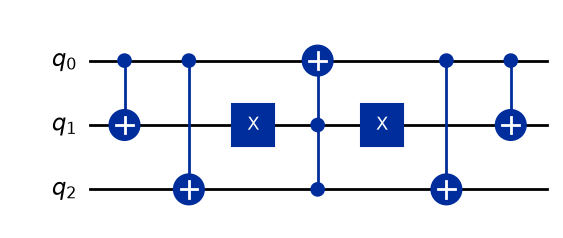

In [7]:
ENCODINGS = {"binary": binary, "Gray": gray, "one-hot": unary}
DECODERS = {"binary": lambda c: int(c, 2), "Gray": decode_gray, "one-hot": decode_unary}


def neighbor_step(encoding, m):
    """Circuit that exchanges the codes of m and m + 1.

    Every other code is left alone.
    """
    code_m, code_next = ENCODINGS[encoding](m), ENCODINGS[encoding](m + 1)
    num_bits = len(code_m)
    circuit = QuantumCircuit(num_bits, name=f"E_{m}")
    if encoding == "one-hot":
        circuit.swap(m, m + 1)
        return circuit

    def bit(code, k):
        return code[-1 - k]

    differing = [k for k in range(num_bits) if bit(code_m, k) != bit(code_next, k)]
    pivot, others = differing[0], differing[1:]
    # Make the two codes differ only in the pivot bit.
    for k in others:
        circuit.cx(pivot, k)
    # The CX gates leave the code whose pivot bit is 0 unchanged,
    # so its other bits are the values the CCX controls test for.
    reference = code_m if bit(code_m, pivot) == "0" else code_next
    controls = [k for k in range(num_bits) if k != pivot]
    zeros = [k for k in controls if bit(reference, k) == "0"]
    for k in zeros:                        # a control that must be 0 is sandwiched by X
        circuit.x(k)
    circuit.ccx(controls[0], controls[1], pivot)
    for k in zeros:
        circuit.x(k)
    for k in reversed(others):             # undo the CX gates
        circuit.cx(pivot, k)
    return circuit


def is_exchange(circuit, code_a, code_b, check_all):
    """True if the circuit swaps the two codes.

    With check_all, every other bitstring must also be left unchanged.
    """
    U = Operator(circuit).data.real
    i, j = int(code_a, 2), int(code_b, 2)
    P = np.eye(U.shape[0])
    P[[i, j]] = P[[j, i]]
    if check_all:
        return np.allclose(U, P)
    return np.allclose(U[:, [i, j]], P[:, [i, j]])


reference = generate_preset_pass_manager(
    basis_gates=["cx", "rz", "sx", "x"], optimization_level=1
)
print("CX gates needed for the neighbor step m -> m + 1 (and back):")
for encoding, encode in ENCODINGS.items():
    row = []
    for m in range(N - 1):
        step = neighbor_step(encoding, m)
        # For one-hot only the valid codes matter;
        # SWAP also moves some invalid patterns.
        check_all = encoding != "one-hot"
        ok = is_exchange(step, encode(m), encode(m + 1), check_all=check_all)
        cx = dict(reference.run(step).count_ops()).get("cx", 0)
        row.append(f"{cx:>2}{'' if ok else '!'}")
    print(f"  {encoding:8s}", "  ".join(row), f"  ({len(encode(0))} qubits)")
neighbor_step("binary", 3).draw("mpl")

Every circuit passed the check (a failure would be marked with `!`). The CX
counts per step, for $m = 0$ to 6, are 6 to 10 for binary, with the worst
case at $3 \to 4$; 6 for every Gray step; and 3 for every one-hot step. One-hot
uses the most qubits, eight against three, and has 248 invalid patterns, but
its steps are the cheapest and they touch only two neighboring qubits.

The Hamming distance alone does not predict these numbers: Gray changes one
bit and costs 6 CX, while one-hot changes two bits and costs 3. The difference
is the condition. In Gray, flipping the one bit would also change other codes,
so the flip must be conditioned on the other two bits, and that conditioned
flip is a CCX, which Notebook 02 counted at 6 CX. In one-hot, every valid
code other than $m$ and $m+1$ has bits $m$ and $m+1$ both 0, so a SWAP of
those two bits leaves it alone without any condition, and a SWAP is 3 CX.
Binary needs the same CCX as Gray, plus a pair of CX gates before and after
it for each extra bit that differs: $6 + 2 = 8$ for one extra bit and
$6 + 4 = 10$ for two, as at $3 \to 4$.

A common mistake is to think that the encoding with the fewest qubits is
always the best. That is wrong: binary needs the fewest qubits, but its
neighbor steps cost 6 to 10 CX gates, never fewer than Gray's 6, and the cost
varies with $m$. One-hot
spends more qubits, and must guard against invalid patterns with a penalty,
but each step is a single SWAP. The idea is tempting because qubits are the
scarcest resource on today's machines. Gates matter as much, because every
gate adds error (Notebook 02, Exercise 7). Unit 3's deuteron notebook compares
exactly these three encodings and reaches the same trade-off.

**Check.** In the one-hot encoding, what does $E_3$ (SWAP of bits 3 and 4) do
to the invalid pattern $00011000$?

## The experiment: one neighbor step in each encoding

For each encoding and each $m$ from 0 to 6, we prepare the code of $m$, apply
$E_m$, measure, and decode. Every shot should decode to $m+1$.

### Encoding

Prepare the code of $m$ with NOT gates, as in Notebook 00.

In [8]:
def prepare(code):
    circuit = QuantumCircuit(len(code))
    for k in range(len(code)):
        if code[-1 - k] == "1":
            circuit.x(k)
    return circuit

### Operator

Apply the neighbor step $E_m$ from the previous section, then measure every
qubit.

In [9]:
circuits, expected = {}, {}
for encoding, encode in ENCODINGS.items():
    for m in range(N - 1):
        circuit = prepare(encode(m)).compose(neighbor_step(encoding, m))
        circuit.measure_all()
        circuits[(encoding, m)] = circuit
        expected[(encoding, m)] = m + 1
print(len(circuits), "circuits")

21 circuits


### Execution

In [10]:
isa_circuits = {}
for target in targets:
    pass_manager = generate_preset_pass_manager(
        backend=target.backend, optimization_level=1
    )
    isa_circuits[target.label] = {
        key: pass_manager.run(c) for key, c in circuits.items()
    }

pubs = {
    label: [(isa,) for isa in group.values()]
    for label, group in isa_circuits.items()
}

results = {}
for target in targets:
    job = target.sampler.run(pubs[target.label], shots=SETTINGS.shots)
    # wait() returns None if a hardware job failed or you stopped waiting.
    results[target.label] = target.wait(job)

### Analysis

Each shot is decoded. We count three kinds of shot: decoded to $m+1$
(correct), decoded to some other value (wrong), and invalid (no value; only
possible for one-hot). For one-hot shots we also report the average penalty
$(w-1)^2$.

In [11]:
for label, result in results.items():
    if result is None:
        continue
    print(f"{label}, {SETTINGS.shots} shots per circuit")
    for encoding in ENCODINGS:
        correct = wrong = invalid = 0
        penalty_sum = 0
        for key, pub_result in zip(circuits, result):
            if key[0] != encoding:
                continue
            for code, count in pub_result.data.meas.get_counts().items():
                value = DECODERS[encoding](code)
                if value is None:
                    invalid += count
                elif value == expected[key]:
                    correct += count
                else:
                    wrong += count
                penalty_sum += one_hot_penalty(code) * count
        total = correct + wrong + invalid
        line = (
            f"  {encoding:8s} correct {correct / total:.3f},"
            f" wrong {wrong / total:.3f}, invalid {invalid / total:.3f}"
        )
        if encoding == "one-hot":
            line += f", average penalty {penalty_sum / total:.3f}"
        print(line)

aer, 4096 shots per circuit
  binary   correct 1.000, wrong 0.000, invalid 0.000
  Gray     correct 1.000, wrong 0.000, invalid 0.000
  one-hot  correct 1.000, wrong 0.000, invalid 0.000, average penalty 0.000


On the simulator every shot is correct in every encoding, and no one-hot shot
is invalid. On hardware the three rows differ, and the exercises ask you to
explain how.

## Exercises

1. Write 11 in four-bit binary and four-bit Gray code. How many bits does the
   one-hot encoding of 16 values need? Decode the four-bit Gray code $0111$.
2. Expand the two-bit one-hot penalty $(x_0 + x_1 - 1)^2$ with $x^2 = x$, and
   check its value on $00$, $01$, $10$ and $11$.
3. Store $N = 5$ values in three-bit binary. Which patterns are invalid? Write
   a penalty, a sum of products of bits, that is 0 on the valid patterns and
   positive on the invalid ones. (Hint: every invalid pattern has bit 2 equal
   to 1 and at least one other bit equal to 1.)
4. For four-bit binary, find the Hamming distance between the codes of $m$
   and $m+1$ for $m = 0$ to 14. Which step changes the most bits? What is the
   distance for every step in four-bit Gray code?
5. (Uses Notebook 02.) The circuit of Example 3 adds one modulo 4. Its
   inverse subtracts one. Using the fact that CX and $X$ are their own
   inverses, write the subtract-one circuit and check it on all four inputs.
6. True or false: binary is always the best encoding, because it uses the
   fewest qubits. Give the reason.
7. (hardware) Set `skip_hardware=False` in the Setup cell and run the
   notebook. Rank the three encodings by their fraction of correct shots. Does
   the ranking follow the CX counts? How large is the invalid fraction for
   one-hot? Compare it with the random scatter $\sqrt{p(1-p)/S}$ of a
   fraction $p$ from $S$ shots, using the scatter rule of Notebook 00. (Here
   $S$ is the number of shots, to keep it apart from $N$, the number of
   values.)
8. (hardware) For the one-hot rows, what penalty do the invalid shots
   receive? If a search tried to make the average penalty small, which
   invalid patterns would it push hardest against?

## What you can now do

1. Encode and decode the values 0 to 7 in binary, Gray and one-hot codes.
2. Count the bits each encoding needs for $N$ values and identify invalid
   bitstrings.
3. Write a penalty that is 0 on valid bitstrings and positive on invalid
   ones, and expand it with $x^2 = x$.
4. Build the neighbor step in each encoding and compare the gate costs.

## Solutions

**Check, encoding and decoding.** $2^6 = 64 < 100 \le 128 = 2^7$, so 7 bits.

**Check, Gray code.** Top bit $b_2 = 0$; $b_1 = 0 \oplus 1 = 1$;
$b_0 = 1 \oplus 1 = 0$. So $b = 010$, which is 2. Check: $g(2) = 010 \oplus 001 = 011$.

**Check, one-hot.** $010$ and $101$ differ in all three positions: distance 3.

**Check, penalties.** Hamming weight 0, so the penalty is $(0 - 1)^2 = 1$.

**Check, adding one.** Yes: each column has one 1. Column 3 is the input
$m = 3$, which goes to $0$, so its 1 is in row 0.

**Check, neighbor step.** Bits 4 and 3 are both 1, so exchanging them changes
nothing: $00011000$ stays $00011000$. SWAP never changes the Hamming weight, so
it never turns an invalid pattern into a valid one or the reverse.

**Exercise 1.** $11 = 8 + 2 + 1 = 1011_2$. Gray:
$1011 \oplus 0101 = 1110$. One-hot needs 16 bits. Decode $0111$:

$$b_3 = 0, \quad b_2 = 0 \oplus 1 = 1, \quad b_1 = 1 \oplus 1 = 0, \quad b_0 = 0 \oplus 1 = 1,$$

so $b = 0101 = 5$. **Check.** $g(5) = 0101 \oplus 0010 = 0111$.

**Exercise 2.** $(x_0 + x_1 - 1)^2 = x_0^2 + x_1^2 + 2x_0x_1 - 2x_0 - 2x_1 + 1$.
With $x^2 = x$: $1 - x_0 - x_1 + 2x_0x_1$. Values: $00 \to 1$, $01 \to 0$,
$10 \to 0$, $11 \to 1 - 1 - 1 + 2 = 1$. The two valid codes get 0.

**Exercise 3.** The valid codes are $000$ to $100$ (0 to 4); $101$, $110$ and
$111$ are invalid. The penalty $x_2x_1 + x_2x_0$ is 0 whenever $x_2 = 0$, and
also for $100$. It is 1 for $101$ and $110$, and 2 for $111$. All invalid
patterns get a positive value and all valid ones get 0.

**Exercise 4.** The distances for $m = 0, \dots, 14$ are
1, 2, 1, 3, 1, 2, 1, 4, 1, 2, 1, 3, 1, 2, 1. The worst step is $7 \to 8$
($0111 \to 1000$), which changes all four bits. In Gray code every distance is
1, by construction.

**Exercise 5.** The inverse of a product is the product of the inverses in
reverse order: $(X_0\,\mathrm{CX})^{-1} = \mathrm{CX}^{-1} X_0^{-1}$, which
as a circuit (left to right) means $X_0$ first, then CX. Each gate is its own
inverse. Check: $00 \to 01 \to 11$ ($0 \to 3$), $01 \to 00 \to 00$
($1 \to 0$), $10 \to 11 \to 01$ ($2 \to 1$), $11 \to 10 \to 10$ ($3 \to 2$).
Each value drops by one modulo 4.

**Exercise 6.** False. Binary uses the fewest qubits, but its neighbor steps
cost more gates and the cost varies with $m$. Gray and one-hot trade qubits
or validity checks for cheaper, more uniform steps. Which is best depends on
which operations the problem needs and on whether qubits or gates are
scarcer.

**Exercise 7.** Expect one-hot (3 CX per step) to have the highest correct
fraction, Gray (6) next, and binary (6 to 10) lowest, with the binary steps
for $m = 3$ worst. The ranking may be blurred if the transpiler has to add
SWAP gates to connect qubits that are not neighbors on the chip; compare the
two-qubit gate counts of the transpiled circuits. Expect an invalid one-hot
fraction of a few percent. Each one-hot row pools $7 \times 4096$ shots, so
with $p = 0.03$ the scatter is about
$\sqrt{0.03 \times 0.97 / 28672} \approx 0.001$. A fraction of a few percent is
many times the scatter, more than three times by the scatter rule of
Notebook 00, so it is a real hardware effect.

**Exercise 8.** Most invalid shots have Hamming weight 0 or 2: a single bit
error either clears the 1 or sets a second bit. Clearing the 1 should be the
more common of the two, because a qubit that holds 1 can relax to 0 during
readout (Notebook 00). Both get penalty 1. Weight 3
gets penalty 4, but needs two errors and is rare. A search that lowers the
average penalty pushes hardest against the patterns with the most 1s, because
the penalty $(w-1)^2$ grows as the square of the extra weight.

## Terms introduced in this notebook

| Term | Meaning |
|---|---|
| encoding | a rule that assigns each value of a problem a bitstring |
| decoding | finding the value a bitstring stands for |
| binary encoding | $m$ written as a binary number; $\log_2 N$ bits |
| Gray code | $g = b \oplus (b \gg 1)$; codes of $m$ and $m+1$ differ in one bit |
| unary (one-hot) encoding | $N$ bits, with only bit $m$ set for the value $m$ |
| Hamming weight | the number of 1s in a bitstring |
| Hamming distance | the number of positions in which two bitstrings differ |
| valid, invalid bitstring | a bitstring that does, or does not, stand for a value |
| penalty | a function of the bits that is 0 on valid bitstrings and positive on invalid ones |
| neighbor step $E_m$ | the reversible operation that exchanges the values $m$ and $m+1$ and leaves the others alone |